# Heart Disease Prediction — CodeAlpha ML Internship, Task 4

Predict whether a patient has heart disease from structured clinical data (UCI Cleveland dataset, `heart.csv`).

**Models compared:** Logistic Regression, SVM, Random Forest, XGBoost, each tuned with cross-validated grid search inside a leakage-free `Pipeline`.

> **Disclaimer:** this is an educational project, not a diagnostic tool. It must not be used for real medical decisions.

## Data dictionary

| Column | Meaning | Values |
|---|---|---|
| age | age in years | |
| sex | sex | 1 = male, 0 = female |
| cp | chest pain type | 0 typical angina, 1 atypical angina, 2 non-anginal, 3 asymptomatic |
| trestbps | resting blood pressure (mm Hg) | |
| chol | serum cholesterol (mg/dl) | |
| fbs | fasting blood sugar > 120 mg/dl | 1 = true, 0 = false |
| restecg | resting ECG | 0 normal, 1 ST-T wave abnormality, 2 probable left ventricular hypertrophy |
| thalach | maximum heart rate achieved | |
| exang | exercise-induced angina | 1 = yes, 0 = no |
| oldpeak | ST depression induced by exercise | |
| slope | slope of peak exercise ST segment | 0 upsloping, 1 flat, 2 downsloping |
| ca | major vessels (0-3) coloured by fluoroscopy | 4 is an error code |
| thal | thalassemia | 0 is an error code, 1 fixed defect, 2 normal, 3 reversible defect |
| target | label | 1 = disease, 0 = no disease (see the label check in section 2) |

## 1. Import important libraries

In [1]:
import warnings
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load and clean the data

Three cleaning steps:
1. Drop duplicate rows (before splitting, so a duplicate cannot appear in both train and test).
2. Turn the dataset's **error codes** (`thal = 0`, `ca = 4`) into real missing values, so the imputers in the pipeline have something to do.
3. Run a **label sanity check** (below).

In [2]:
data = pd.read_csv("heart.csv")
data.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
5,58,0,0,100,248,0,0,122,0,1.0,1,0,2,1
6,58,1,0,114,318,0,2,140,0,4.4,0,3,1,0
7,55,1,0,160,289,0,0,145,1,0.8,1,1,3,0
8,46,1,0,120,249,0,0,144,0,0.8,2,0,3,0
9,54,1,0,122,286,0,0,116,1,3.2,1,2,2,0


In [3]:
print("Rows:", len(data), "| Duplicate rows:", data.duplicated().sum())

Rows: 1025 | Duplicate rows: 723


In [4]:
data = data.drop_duplicates().reset_index(drop=True)

print("thal == 0:", (data["thal"] == 0).sum(), "| ca == 4:", (data["ca"] == 4).sum())

thal == 0: 2 | ca == 4: 4


In [6]:
data.loc[data["thal"] == 0, "thal"] = np.nan
data.loc[data["ca"] == 4, "ca"] = np.nan

print("\nShape after cleaning:", data.shape)


Shape after cleaning: (302, 14)


In [7]:
print("\nMissing values per column:")
print(data.isna().sum()[data.isna().sum() > 0])
data.head()


Missing values per column:
ca      4
thal    2
dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2.0,3.0,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0.0,3.0,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0.0,3.0,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1.0,3.0,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3.0,2.0,0


### Label sanity check

Clinically, patients **with** heart disease tend to have a **lower** maximum heart rate, **higher** ST depression (`oldpeak`) and **more** exercise-induced angina. Some copies of this dataset appear to have the `target` column reversed relative to its documentation. The check below compares the group means and, if they look reversed, flips `target` so that **1 = disease** holds for the rest of the notebook. Set `FLIP_LABELS` by hand if you disagree.

In [8]:
check_cols = ["thalach", "oldpeak", "exang"]
means = data.groupby("target")[check_cols].mean().round(2)
print("Group means BEFORE any change:")
display(means)

looks_reversed = (
    means.loc[1, "thalach"] > means.loc[0, "thalach"]
    and means.loc[1, "oldpeak"] < means.loc[0, "oldpeak"]
    and means.loc[1, "exang"] < means.loc[0, "exang"]
)

FLIP_LABELS = bool(looks_reversed)   # override with True / False if needed
if FLIP_LABELS:
    data["target"] = 1 - data["target"]
    print("target=1 looked like the healthier group, so labels were flipped (now 1 = disease).")
    display(data.groupby("target")[check_cols].mean().round(2))
else:
    print("Group means match the clinical expectation, so labels were kept (1 = disease).")

Group means BEFORE any change:


,thalach,oldpeak,exang
target,,,
0,139.10,1.59,0.55
1,158.38,0.59,0.14


target=1 looked like the healthier group, so labels were flipped (now 1 = disease).


,thalach,oldpeak,exang
target,,,
0,158.38,0.59,0.14
1,139.10,1.59,0.55


## 3. Exploratory data analysis

In [9]:
print("Class balance (1 = disease):")
display(data["target"].value_counts().rename({0: "no disease", 1: "disease"}).to_frame("count")
        .assign(share=lambda d: (d["count"] / d["count"].sum()).round(3)))
data.describe().round(2)

Class balance (1 = disease):


,count,share
target,,
no disease,164,0.543
disease,138,0.457


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,298.00,300.00,302.00
mean,54.42,0.68,0.96,131.60,246.50,0.15,0.53,149.57,0.33,1.04,1.40,0.67,2.33,0.46
std,9.05,0.47,1.03,17.56,51.75,0.36,0.53,22.90,0.47,1.16,0.62,0.94,0.59,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,1.00,0.00
25%,48.00,0.00,0.00,120.00,211.00,0.00,0.00,133.25,0.00,0.00,1.00,0.00,2.00,0.00
50%,55.50,1.00,1.00,130.00,240.50,0.00,1.00,152.50,0.00,0.80,1.00,0.00,2.00,0.00
75%,61.00,1.00,2.00,140.00,274.75,0.00,1.00,166.00,1.00,1.60,2.00,1.00,3.00,1.00
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,2.00,3.00,3.00,1.00


**Disease rate by category** (bar height = share of patients with disease, label = patients in that group):

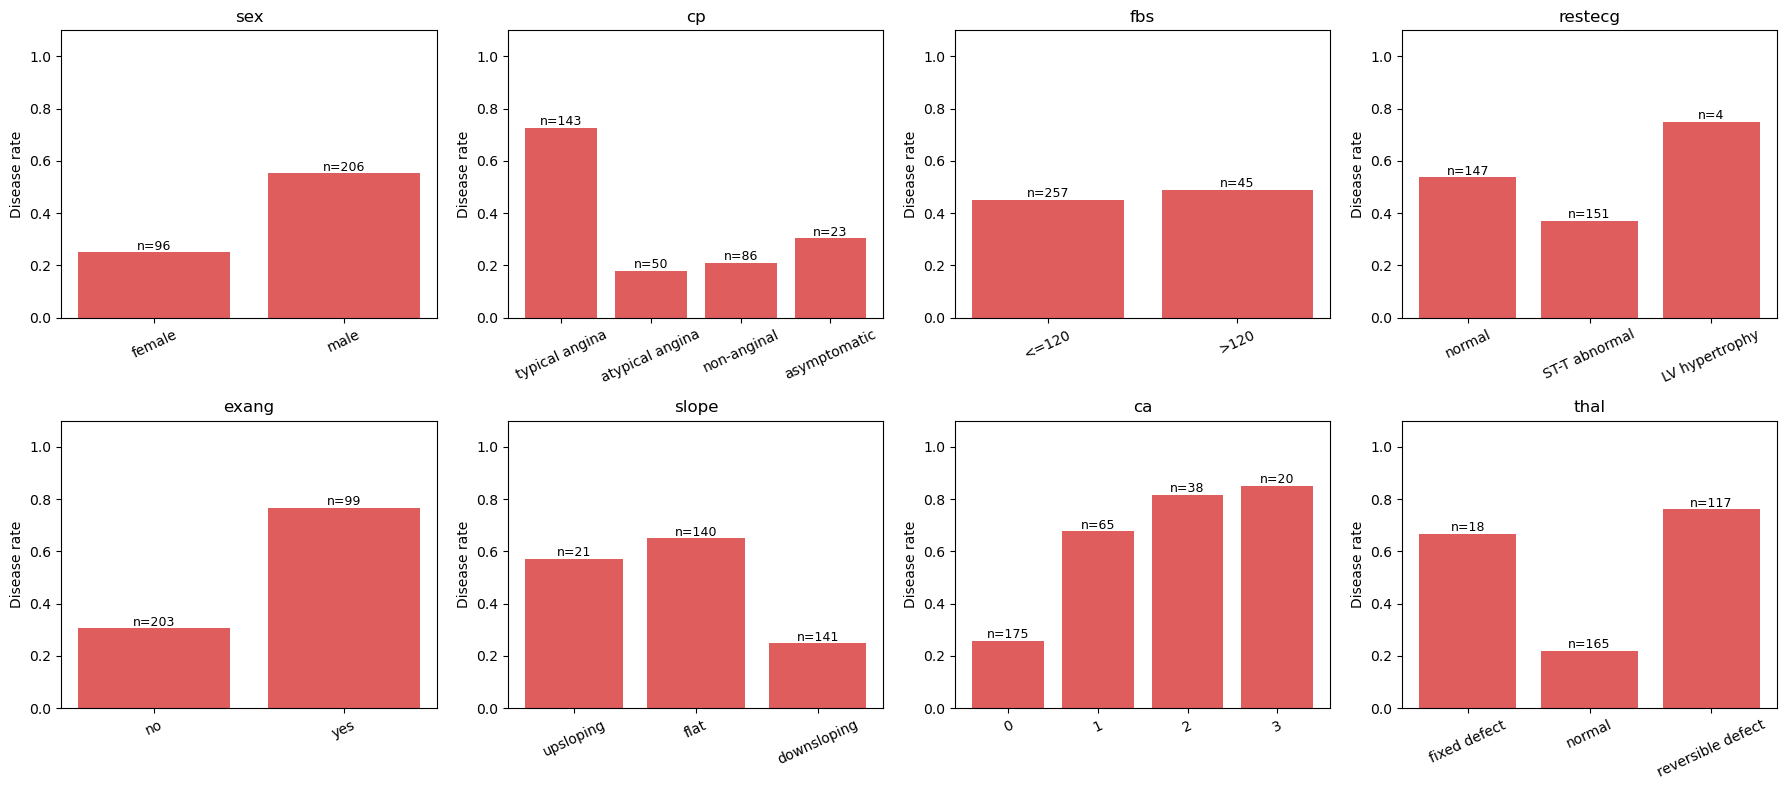

In [10]:
label_maps = {
    "sex":     {0: "female", 1: "male"},
    "cp":      {0: "typical angina", 1: "atypical angina", 2: "non-anginal", 3: "asymptomatic"},
    "fbs":     {0: "<=120", 1: ">120"},
    "restecg": {0: "normal", 1: "ST-T abnormal", 2: "LV hypertrophy"},
    "exang":   {0: "no", 1: "yes"},
    "slope":   {0: "upsloping", 1: "flat", 2: "downsloping"},
    "ca":      {0.0: "0", 1.0: "1", 2.0: "2", 3.0: "3"},
    "thal":    {1.0: "fixed defect", 2.0: "normal", 3.0: "reversible defect"},
}

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, (col, mapping) in zip(axes.ravel(), label_maps.items()):
    g = data.groupby(col)["target"].agg(["mean", "count"])
    names = [mapping.get(i, str(i)) for i in g.index]
    bars = ax.bar(names, g["mean"], color="tab:red", alpha=0.75)
    for b, n in zip(bars, g["count"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"n={n}", ha="center", fontsize=9)
    ax.set_ylim(0, 1.1)
    ax.set_title(col)
    ax.set_ylabel("Disease rate")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

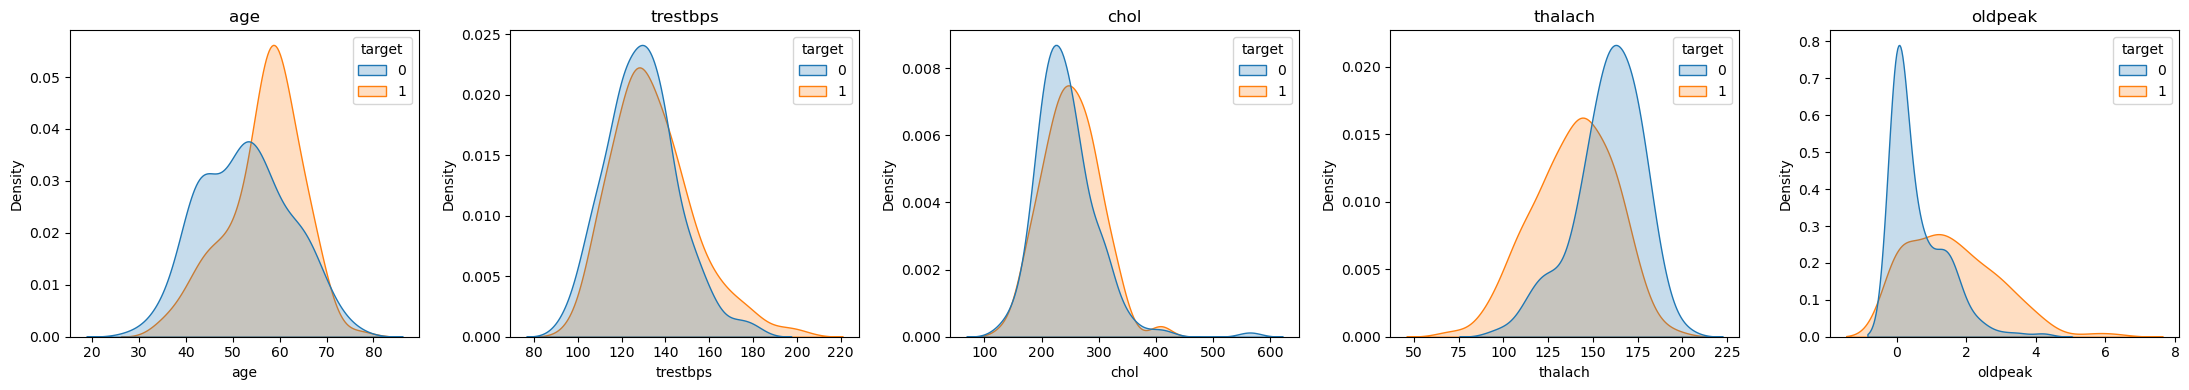

In [11]:
continuous_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, col in zip(axes, continuous_cols):
    sns.kdeplot(data=data, x=col, hue="target", common_norm=False, fill=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

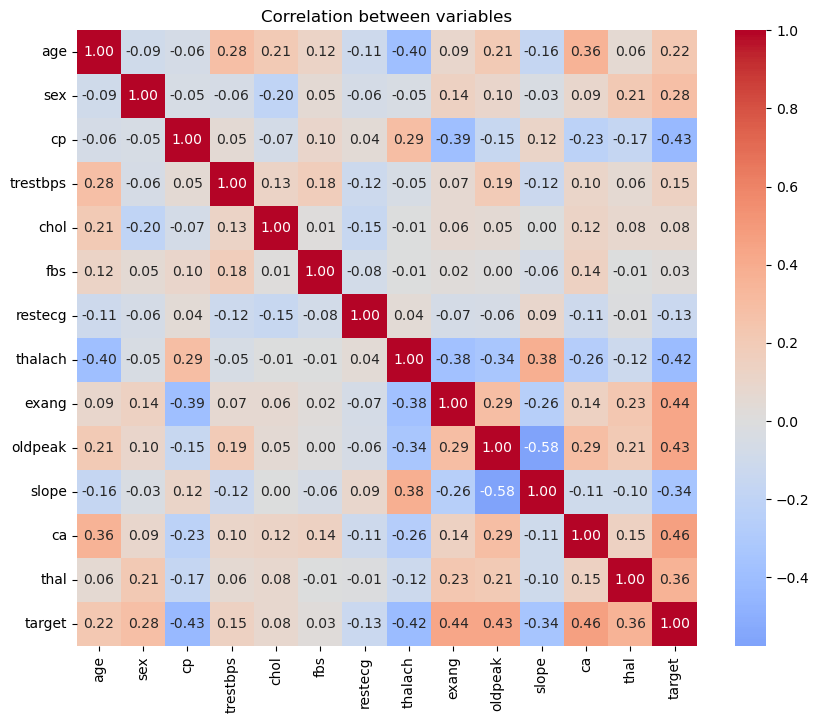

In [12]:
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between variables")
plt.show()

**Outliers (IQR rule).** They are kept, because extreme clinical values can be genuine patients.

### Observations

- **Class balance:** 138 patients with disease (45.7%) and 164 without, so the classes are roughly balanced and accuracy is a meaningful metric.
- **Sex:** the sample is 68% male (206 vs 96). The disease rate is about 55% in men and 25% in women, so the data over-represent men and women have a lower disease rate here.
- **Strongest categorical signals:** the disease rate rises steadily with the number of coloured vessels (`ca`): about 26% with 0 vessels, then 68%, 82% and 85% with 1, 2 and 3. Exercise-induced angina shows a large gap (31% without vs 77% with). For `thal`, the normal group has a 22% disease rate against 76% for reversible defect (117 patients) and 67% for fixed defect (only 18 patients).
- **Fasting blood sugar barely matters:** 45% vs 49% disease rate for the two groups.
- **Continuous variables:** patients with disease reach a lower maximum heart rate (`thalach` peaks near 145 vs about 165). ST depression (`oldpeak`) is concentrated near 0 in healthy patients and spreads out to 6 in patients with disease. Patients with disease are slightly older (peak near 58-60). Resting blood pressure and cholesterol overlap almost completely between the two groups, so they are weak signals on their own.
- **Correlations:** the features most correlated with the target are `ca` (0.46), `exang` (0.44), `oldpeak` (0.43), `cp` (-0.43) and `thalach` (-0.42). The weakest are `fbs` (0.03) and `chol` (0.08). The strongest correlation between two features is `oldpeak` and `slope` (-0.58). No pair exceeds 0.6 in absolute value, so there is no severe multicollinearity.
- **Caution on category names:** for `cp`, `slope` and `restecg`, the text names from the data dictionary do not behave as expected clinically (for example, the group labelled "typical angina" has the highest disease rate), and the `restecg` group labelled "LV hypertrophy" has only 4 patients. The names may not match the original coding, so these three variables are interpreted by their numeric codes rather than by their names. This does not affect model training, which only uses the codes.

In [13]:
rows = []
for col in continuous_cols:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (data[col] < low) | (data[col] > high)
    rows.append({"feature": col, "min": data[col].min(), "max": data[col].max(),
                 "lower bound": round(low, 1), "upper bound": round(high, 1),
                 "outliers": int(flagged.sum()), "outlier %": round(flagged.mean() * 100, 1)})
pd.DataFrame(rows)

,feature,min,max,lower bound,upper bound,outliers,outlier %
0,age,29.0,77.0,28.5,80.5,0,0.0
1,trestbps,94.0,200.0,90.0,170.0,9,3.0
2,chol,126.0,564.0,115.4,370.4,5,1.7
3,thalach,71.0,202.0,84.1,215.1,1,0.3
4,oldpeak,0.0,6.2,-2.4,4.0,5,1.7


In [14]:
for col in continuous_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    flagged = data[(data[col] < lower) | (data[col] > upper)]
    print(f"\n{col}: lower = {lower:.2f}, upper = {upper:.2f}")
    print(flagged[[col, "target"]].to_string(index=True))


age: lower = 28.50, upper = 80.50
Empty DataFrame
Columns: [age, target]
Index: []

trestbps: lower = 90.00, upper = 170.00
     trestbps  target
28        180       1
44        178       1
76        174       1
112       180       0
124       192       1
142       200       1
226       172       0
248       180       1
271       178       0

chol: lower = 115.38, upper = 370.38
     chol  target
104   417       0
128   564       0
144   409       1
183   394       0
260   407       1

thalach: lower = 84.12, upper = 215.12
     thalach  target
188       71       1

oldpeak: lower = -2.40, upper = 4.00
     oldpeak  target
6        4.4       1
13       4.2       1
51       5.6       1
63       6.2       1
271      4.2       0


### The IQR method was used to identify potential outliers in the numerical features.
### Since extreme medical measurements may represent genuine patient conditions, the observations were retained rather than automatically removed. 
### This preserves potentially useful clinical information for model training.

## 4. Train/test split and preprocessing

The split happens **before** any scaling or imputing. All preprocessing lives inside the `Pipeline`, so it is fitted on the training folds only.

In [15]:
X = data.drop(columns="target")
y = data["target"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, " Test:", X_test.shape)

numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

Train: (241, 13)  Test: (61, 13)


## 5. Models and hyperparameter search

The four algorithms named in the task: Logistic Regression, SVM, Random Forest and XGBoost. Each is tuned by 5-fold stratified grid search on **ROC-AUC**, using the training set only.

In [16]:
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        {"classifier__C": [0.01, 0.1, 1, 10, 100],
         "classifier__class_weight": [None, "balanced"]},
    ),
    "SVM": (
        SVC(probability=True, random_state=RANDOM_STATE),
        {"classifier__kernel": ["rbf", "linear"],
         "classifier__C": [0.1, 1, 10],
         "classifier__gamma": ["scale", 0.01, 0.1],
         "classifier__class_weight": [None, "balanced"]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {"classifier__n_estimators": [100, 200],
         "classifier__max_depth": [4, 6, 10, None],
         "classifier__min_samples_leaf": [1, 2, 5],
         "classifier__class_weight": [None, "balanced"]},
    ),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1),
        {"classifier__n_estimators": [100, 200],
         "classifier__max_depth": [2, 3, 4],
         "classifier__learning_rate": [0.03, 0.1],
         "classifier__min_child_weight": [1, 3]},
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [17]:
results, fitted_models, test_probs = [], {}, {}

for name, (clf, grid) in models.items():
    print(f"Training {name} ...")
    pipe = Pipeline([("preprocessor", preprocessor), ("classifier", clf)])
    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)

    best = search.best_estimator_
    y_pred = best.predict(X_test)
    y_prob = best.predict_proba(X_test)[:, 1]

    fitted_models[name] = best
    test_probs[name] = y_prob
    results.append({
        "Model": name,
        "CV ROC-AUC": search.best_score_,
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Test precision": precision_score(y_test, y_pred, zero_division=0),
        "Test recall": recall_score(y_test, y_pred, zero_division=0),
        "Test F1": f1_score(y_test, y_pred, zero_division=0),
        "Test ROC-AUC": roc_auc_score(y_test, y_prob),
        "Best parameters": str(search.best_params_),
    })

results_df = pd.DataFrame(results).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
display(results_df.drop(columns="Best parameters").round(4))

Training Logistic Regression ...
Training SVM ...
Training Random Forest ...
Training XGBoost ...


,Model,CV ROC-AUC,Test accuracy,Test precision,Test recall,Test F1,Test ROC-AUC
0,Random Forest,0.9246,0.8033,0.8077,0.7500,0.7778,0.8939
1,SVM,0.9167,0.8197,0.8148,0.7857,0.8000,0.8907
2,Logistic Regression,0.9160,0.8361,0.8214,0.8214,0.8214,0.9069
3,XGBoost,0.9141,0.8033,0.7667,0.8214,0.7931,0.8885


## 6. Compare models

**Selection rule:** the model with the best cross-validated ROC-AUC (measured on the training set) is chosen. The test set is used only to report how it generalises, never to pick the model.

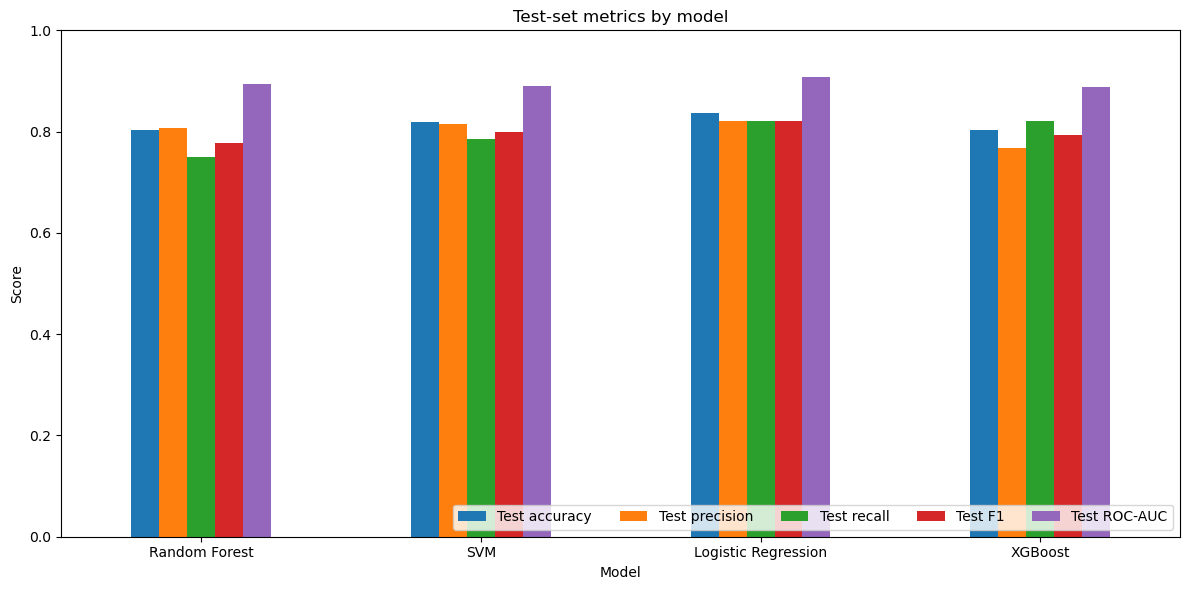

In [18]:
metrics = ["Test accuracy", "Test precision", "Test recall", "Test F1", "Test ROC-AUC"]
results_df.set_index("Model")[metrics].plot(kind="bar", figsize=(12, 6), ylim=(0, 1))
plt.title("Test-set metrics by model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.show()

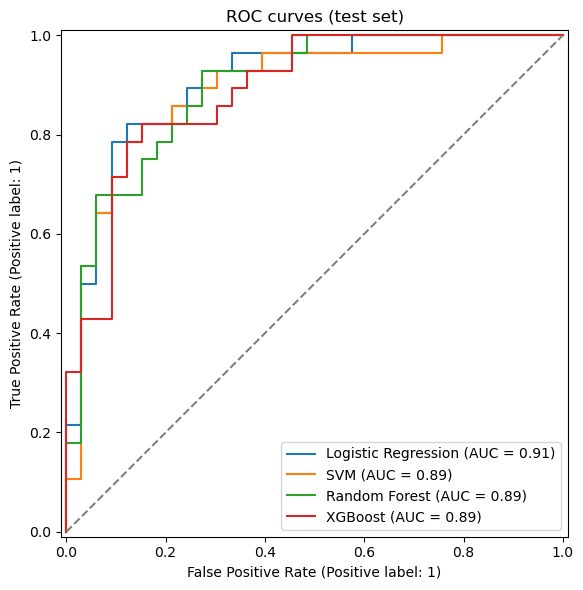

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))
for name in models:
    RocCurveDisplay.from_predictions(y_test, test_probs[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_title("ROC curves (test set)")
plt.tight_layout()
plt.show()

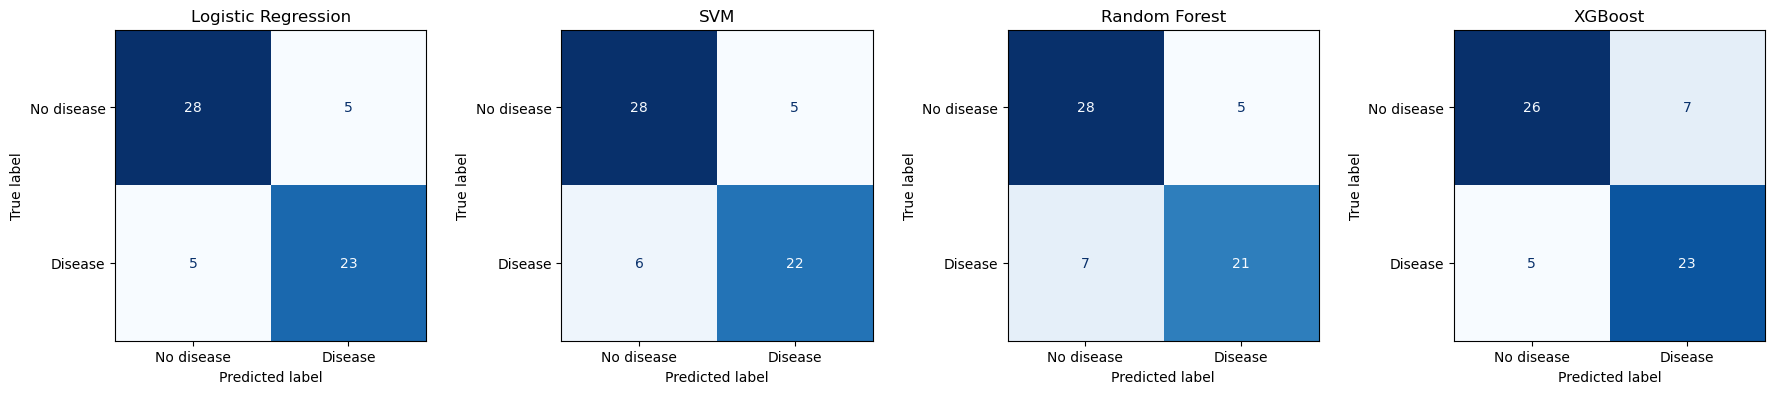

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, fitted_models[name].predict(X_test), labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["No disease", "Disease"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 7. Selected model: final evaluation

In [21]:
best_name = results_df.loc[0, "Model"]
best_pipeline = fitted_models[best_name]
print("Selected model:", best_name)
print("Parameters:", results_df.loc[0, "Best parameters"])

y_hat = best_pipeline.predict(X_test)
y_p = best_pipeline.predict_proba(X_test)[:, 1]
print()
print(classification_report(y_test, y_hat, target_names=["No disease", "Disease"], digits=3))

Selected model: Random Forest
Parameters: {'classifier__class_weight': None, 'classifier__max_depth': 4, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 100}

              precision    recall  f1-score   support

  No disease      0.800     0.848     0.824        33
     Disease      0.808     0.750     0.778        28

    accuracy                          0.803        61
   macro avg      0.804     0.799     0.801        61
weighted avg      0.804     0.803     0.803        61



### How certain are these numbers?

The test set is small (about 60 patients), so a single patient moves the metrics a lot. A bootstrap over the test set gives an honest range.

In [22]:
rng = np.random.default_rng(RANDOM_STATE)
y_true = y_test.to_numpy()
n = len(y_true)
boot = {"accuracy": [], "recall": [], "roc_auc": []}

for _ in range(1000):
    idx = rng.integers(0, n, n)
    if len(np.unique(y_true[idx])) < 2:
        continue
    boot["accuracy"].append(accuracy_score(y_true[idx], y_hat[idx]))
    boot["recall"].append(recall_score(y_true[idx], y_hat[idx], zero_division=0))
    boot["roc_auc"].append(roc_auc_score(y_true[idx], y_p[idx]))

summary = pd.DataFrame({
    metric: {"mean": np.mean(v), "95% low": np.percentile(v, 2.5), "95% high": np.percentile(v, 97.5)}
    for metric, v in boot.items()
}).T.round(3)
print(f"Bootstrap (1000 resamples of the {n}-patient test set), model: {best_name}")
display(summary)

Bootstrap (1000 resamples of the 61-patient test set), model: Random Forest


,mean,95% low,95% high
accuracy,0.803,0.705,0.902
recall,0.749,0.581,0.900
roc_auc,0.895,0.802,0.965


### Recall versus false alarms

In disease screening a **missed case** (false negative) is usually worse than a **false alarm** (false positive). Lowering the decision threshold catches more cases at the cost of more false alarms.

In [23]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    pred = (y_p >= t).astype(int)
    rows.append({
        "threshold": t,
        "precision": round(precision_score(y_true, pred, zero_division=0), 3),
        "recall": round(recall_score(y_true, pred, zero_division=0), 3),
        "missed cases (FN)": int(((pred == 0) & (y_true == 1)).sum()),
        "false alarms (FP)": int(((pred == 1) & (y_true == 0)).sum()),
    })
pd.DataFrame(rows)

,threshold,precision,recall,missed cases (FN),false alarms (FP)
0,0.3,0.703,0.929,2,11
1,0.4,0.727,0.857,4,9
2,0.5,0.808,0.750,7,5
3,0.6,0.826,0.679,9,4


## 8. Which features matter? (permutation importance)

Each original feature is shuffled in turn, and the drop in test ROC-AUC measures how much the model relies on it. Working on the raw columns keeps the result readable (one bar per clinical variable, not per one-hot column).

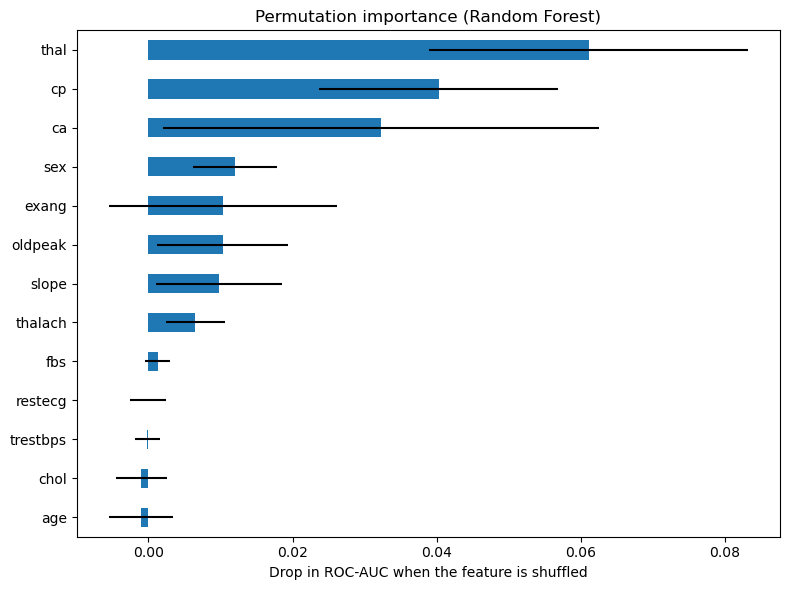

In [24]:
perm = permutation_importance(
    best_pipeline, X_test, y_test,
    scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE, n_jobs=1
)
importance = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                          index=X_test.columns).sort_values("mean")

importance["mean"].plot(kind="barh", xerr=importance["std"], figsize=(8, 6), color="tab:blue")
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.title(f"Permutation importance ({best_name})")
plt.tight_layout()
plt.show()

## 9. Save the model and predict for a new patient

In [26]:
joblib.dump(best_pipeline, "heart_model.joblib")
loaded = joblib.load("heart_model.joblib")
print("Saved heart_model.joblib; reload check (should be True):",
      np.allclose(loaded.predict_proba(X_test)[:, 1], y_p))


def predict_patient(**features):
    # Missing values (np.nan) are allowed: the pipeline imputes them.
    row = pd.DataFrame([features], columns=X.columns)
    prob = float(loaded.predict_proba(row)[0, 1])
    print(f"Estimated probability of heart disease: {prob:.0%}  "
          "(educational model, not medical advice)")
    return prob


Saved heart_model.joblib; reload check (should be True): True


In [27]:
predict_patient(age=70, sex=1, cp=0, trestbps=145, chol=174, fbs=0, restecg=1,
                thalach=125, exang=1, oldpeak=2.6, slope=0, ca=0, thal=3)

Estimated probability of heart disease: 85%  (educational model, not medical advice)


0.8459398616295841

## 10. Summary

- **Label check:** the labels were reversed in this copy of the data. `target = 1` had a higher maximum heart rate (158 vs 139), lower ST depression (0.59 vs 1.59) and less exercise angina (0.14 vs 0.55), so `target` was flipped automatically. After the flip, 138 of 302 patients (45.7%) are labelled as disease.
- **Selected model:** Random Forest (100 trees, `max_depth = 4`, `min_samples_leaf = 2`), chosen for the best cross-validated ROC-AUC (0.925). The four models are close, with cross-validated scores within 0.011 of each other. Logistic Regression had the highest test accuracy (83.6%) but was not chosen, because choosing by test score would leak test information.
- **Test performance (61 patients):** accuracy 80.3% (95% bootstrap range 70.5% to 90.2%), recall 0.75 (0.58 to 0.90), precision 0.81, ROC-AUC 0.894 (0.80 to 0.97). The model found 21 of 28 patients with disease (7 missed) and raised 5 false alarms among 33 patients without it.
- **Recall trade-off:** lowering the decision threshold from 0.5 to 0.3 raises recall from 0.75 to 0.93 (2 missed cases) at the cost of 11 false alarms instead of 5.
- **Top features:** `thal`, `cp` and `ca` have the largest permutation importance, followed by `sex`, `exang`, `oldpeak` and `slope`. `age`, `chol`, `trestbps`, `fbs` and `restecg` contribute almost nothing. The error bars are wide for `ca` and `exang`, and correlated variables (`exang`, `oldpeak`, `slope`, `thalach`) share signal, so each looks less important alone than the group does.
- **Limitations:** about 300 patients from one hospital, a 61-patient test set with wide uncertainty, no external validation, label direction and some category names inferred rather than confirmed, and educational use only.
- **Next steps:** verify the label and category coding against the original UCI source, calibrate the predicted probabilities, add SHAP explanations for individual patients, and test on a second heart-disease dataset.